<a href="https://colab.research.google.com/github/avhrajyoti688-maker/blinkit-grocery-data/blob/main/Blinkit.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Cell 0: upload the Excel file when prompted
from google.colab import files
files.upload()   # choose BlinkIT Grocery Data.xlsxBlinkIT Grocery Data.xlsx

Saving BlinkIT Grocery Data.xlsx to BlinkIT Grocery Data.xlsx


{'BlinkIT Grocery Data.xlsx': b'PK\x03\x04\x14\x00\x06\x00\x08\x00\x00\x00!\x00\xdd+\x8bXl\x01\x00\x00\x10\x05\x00\x00\x13\x00\x08\x02[Content_Types].xml \xa2\x04\x02(\xa0\x00\x02\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\

In [2]:
# Cell 1: imports and load data
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})

df = pd.read_excel("BlinkIT Grocery Data.xlsx")
print(df.shape)
df.head()

(8523, 12)


,Item Fat Content,Item Identifier,Item Type,Outlet Establishment Year,Outlet Identifier,Outlet Location Type,Outlet Size,Outlet Type,Item Visibility,Item Weight,Sales,Rating
0,Regular,FDX32,Fruits and Vegetables,2012,OUT049,Tier 1,Medium,Supermarket Type1,0.100014,15.10,145.4786,5.0
1,Low Fat,NCB42,Health and Hygiene,2022,OUT018,Tier 3,Medium,Supermarket Type2,0.008596,11.80,115.3492,5.0
2,Regular,FDR28,Frozen Foods,2016,OUT046,Tier 1,Small,Supermarket Type1,0.025896,13.85,165.0210,5.0
3,Regular,FDL50,Canned,2014,OUT013,Tier 3,High,Supermarket Type1,0.042278,12.15,126.5046,5.0
4,Low Fat,DRI25,Soft Drinks,2015,OUT045,Tier 2,Small,Supermarket Type1,0.033970,19.60,55.1614,5.0


In [3]:
# Objective 1: Understand the business and its sales performance
# Tasks 1.1 to 1.4: headline numbers
print(f"Records: {len(df):,} | Unique items: {df['Item Identifier'].nunique():,} | Outlets: {df['Outlet Identifier'].nunique()}")
print(f"Total sales: {df['Sales'].sum():,.0f} | Avg sales/record: {df['Sales'].mean():.2f} | Avg rating: {df['Rating'].mean():.2f}")
print("\nItem types:\n", df["Item Type"].value_counts())

Records: 8,523 | Unique items: 1,559 | Outlets: 10
Total sales: 1,201,681 | Avg sales/record: 140.99 | Avg rating: 3.97

Item types:
 Item Type
Fruits and Vegetables    1232
Snack Foods              1200
Household                 910
Frozen Foods              856
Dairy                     682
Canned                    649
Baking Goods              648
Health and Hygiene        520
Soft Drinks               445
Meat                      425
Breads                    251
Hard Drinks               214
Others                    169
Starchy Foods             148
Breakfast                 110
Seafood                    64
Name: count, dtype: int64


In [4]:
# Task 1.2: outlet profile (type, tier, size, year) with sales and rating
outlets = (df.groupby("Outlet Identifier")
             .agg(year=("Outlet Establishment Year", "first"), size=("Outlet Size", "first"),
                  tier=("Outlet Location Type", "first"), type=("Outlet Type", "first"),
                  records=("Sales", "size"), total_sales=("Sales", "sum"),
                  avg_sales=("Sales", "mean"), avg_rating=("Rating", "mean")).round(2))
outlets

,year,size,tier,type,records,total_sales,avg_sales,avg_rating
Outlet Identifier,,,,,,,,
OUT010,2011,Small,Tier 3,Grocery Store,555,78131.57,140.78,3.98
OUT013,2014,High,Tier 3,Supermarket Type1,932,131809.02,141.43,3.95
OUT017,2020,Small,Tier 2,Supermarket Type1,926,129103.96,139.42,3.98
OUT018,2022,Medium,Tier 3,Supermarket Type2,928,131477.78,141.68,3.97
OUT019,2018,Small,Tier 1,Grocery Store,528,73807.58,139.79,4.00
OUT027,2018,Medium,Tier 3,Supermarket Type3,935,130714.67,139.80,3.95
OUT035,2017,Small,Tier 2,Supermarket Type1,930,133103.91,143.12,3.94
OUT045,2015,Small,Tier 2,Supermarket Type1,929,130942.78,140.95,3.96
OUT046,2016,Small,Tier 1,Supermarket Type1,930,132113.37,142.06,3.96


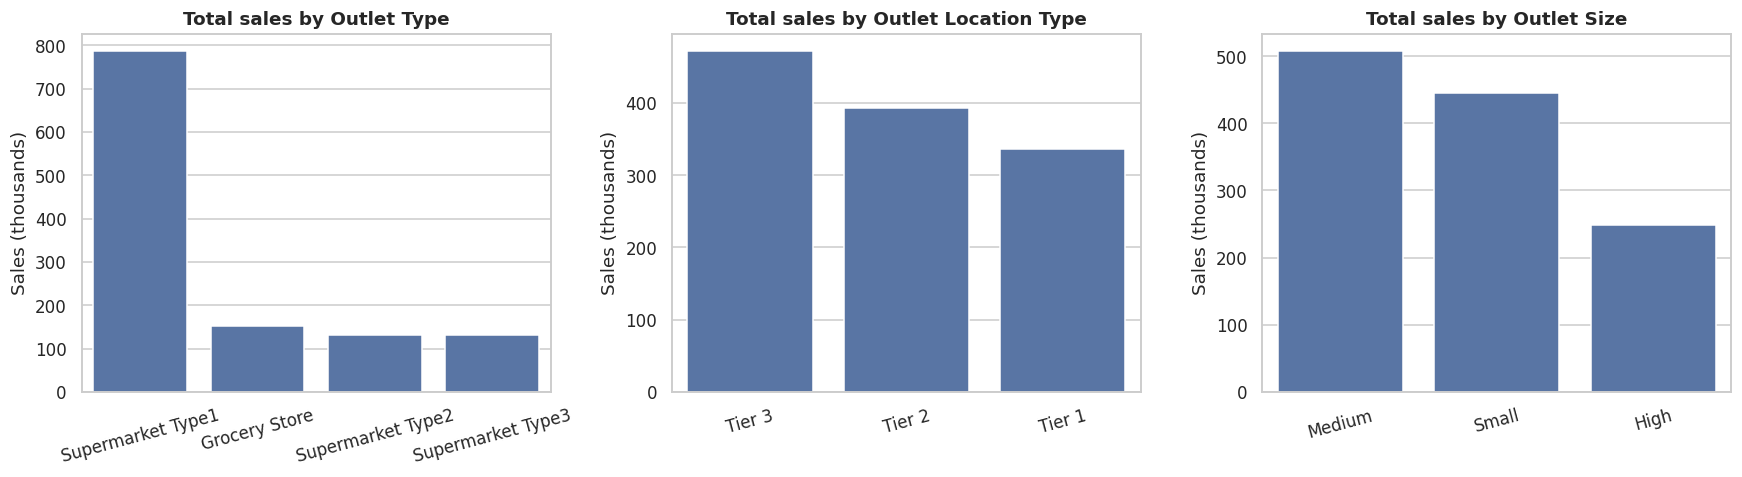

In [5]:
# Sales by outlet type, tier and size
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
for a, col in zip(ax, ["Outlet Type", "Outlet Location Type", "Outlet Size"]):
    s = df.groupby(col)["Sales"].sum().sort_values(ascending=False)
    sns.barplot(x=s.index, y=s.values / 1e3, ax=a)
    a.set_title(f"Total sales by {col}"); a.set_ylabel("Sales (thousands)"); a.set_xlabel("")
    a.tick_params(axis="x", rotation=15)
plt.tight_layout(); plt.show()

In [6]:
#Objective 2: Make sure the data is reliable
# Task 2.1 missing values, and where they sit
print(df.isna().sum()[lambda s: s > 0])
print("\nMissing Item Weight by outlet:")
print(df["Item Weight"].isna().groupby(df["Outlet Identifier"]).sum()[lambda s: s > 0])

# Task 2.2 duplicates
print("\nFull duplicate rows:", df.duplicated().sum())
print("Duplicate (Item, Outlet) pairs:", df.duplicated(["Item Identifier", "Outlet Identifier"]).sum())

Item Weight    1463
dtype: int64

Missing Item Weight by outlet:
Outlet Identifier
OUT019    528
OUT027    935
Name: Item Weight, dtype: int64

Full duplicate rows: 0
Duplicate (Item, Outlet) pairs: 0


In [7]:
# Task 2.4 standardise Item Fat Content
print("Before:", df["Item Fat Content"].value_counts().to_dict())
df["Item Fat Content"] = df["Item Fat Content"].replace({"LF": "Low Fat", "low fat": "Low Fat", "reg": "Regular"})

# Non-consumables (ID prefix NC) can't be Low Fat / Regular
df["Item Category"] = df["Item Identifier"].str[:2].map({"FD": "Food", "DR": "Drinks", "NC": "Non-Consumable"})
df.loc[df["Item Category"] == "Non-Consumable", "Item Fat Content"] = "Non-Edible"
print("After: ", df["Item Fat Content"].value_counts().to_dict())

Before: {'Low Fat': 5089, 'Regular': 2889, 'LF': 316, 'reg': 117, 'low fat': 112}
After:  {'Low Fat': 3918, 'Regular': 3006, 'Non-Edible': 1599}


In [8]:
# Task 2.1 impute Item Weight: same item elsewhere first, then Item Type median
df["Item Weight"] = df["Item Weight"].fillna(df.groupby("Item Identifier")["Item Weight"].transform("mean"))
df["Item Weight"] = df["Item Weight"].fillna(df.groupby("Item Type")["Item Weight"].transform("median"))
print("Missing weights left:", df["Item Weight"].isna().sum())

# Visibility of 0 is impossible for a listed item: treat as missing and re-fill
print("Zero-visibility records:", (df["Item Visibility"] == 0).sum())
df["Item Visibility"] = df["Item Visibility"].replace(0, np.nan)
df["Item Visibility"] = df["Item Visibility"].fillna(df.groupby("Item Identifier")["Item Visibility"].transform("mean"))
df["Item Visibility"] = df["Item Visibility"].fillna(df.groupby("Item Type")["Item Visibility"].transform("median"))

Missing weights left: 0
Zero-visibility records: 526


Sales            outliers:    0 (0.0%)
Item Visibility  outliers:  144 (1.7%)
Item Weight      outliers:    0 (0.0%)
Rating           outliers: 1931 (22.7%)


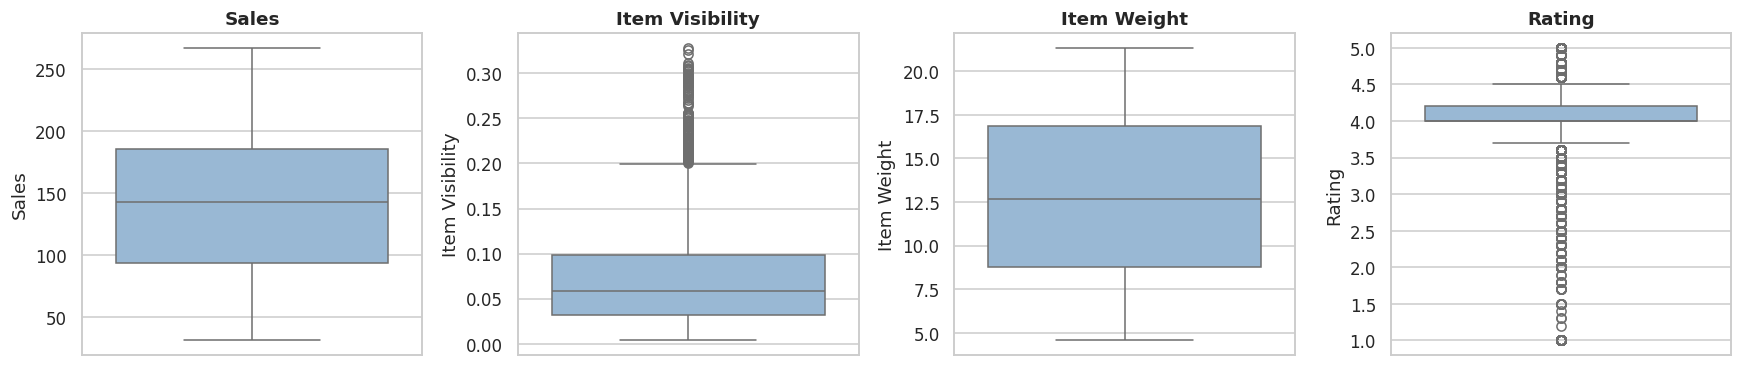

Rating
4.0    0.392
4.3    0.081
4.2    0.079
Name: proportion, dtype: float64


In [9]:
# Task 2.3 outliers (IQR rule): flag, don't delete
def iqr_outliers(s):
    q1, q3 = s.quantile([.25, .75]); i = q3 - q1
    return (s < q1 - 1.5 * i) | (s > q3 + 1.5 * i)

for c in ["Sales", "Item Visibility", "Item Weight", "Rating"]:
    m = iqr_outliers(df[c]); print(f"{c:16s} outliers: {m.sum():4d} ({m.mean():.1%})")

fig, ax = plt.subplots(1, 4, figsize=(16, 3.5))
for a, c in zip(ax, ["Sales", "Item Visibility", "Item Weight", "Rating"]):
    sns.boxplot(y=df[c], ax=a, color="#8fb8de"); a.set_title(c)
plt.tight_layout(); plt.show()

# Rating check: a big spike at 4.0 may be a default value
print(df["Rating"].value_counts(normalize=True).head(3).round(3))

,total,avg,records,share_%
Item Type,,,,
Fruits and Vegetables,178124.1,144.6,1232,14.8
Snack Foods,175433.9,146.2,1200,14.6
Household,135976.5,149.4,910,11.3
Frozen Foods,118558.9,138.5,856,9.9
Dairy,101276.5,148.5,682,8.4
Canned,90706.7,139.8,649,7.5
Baking Goods,81894.7,126.4,648,6.8
Health and Hygiene,68025.8,130.8,520,5.7
Meat,59449.9,139.9,425,4.9


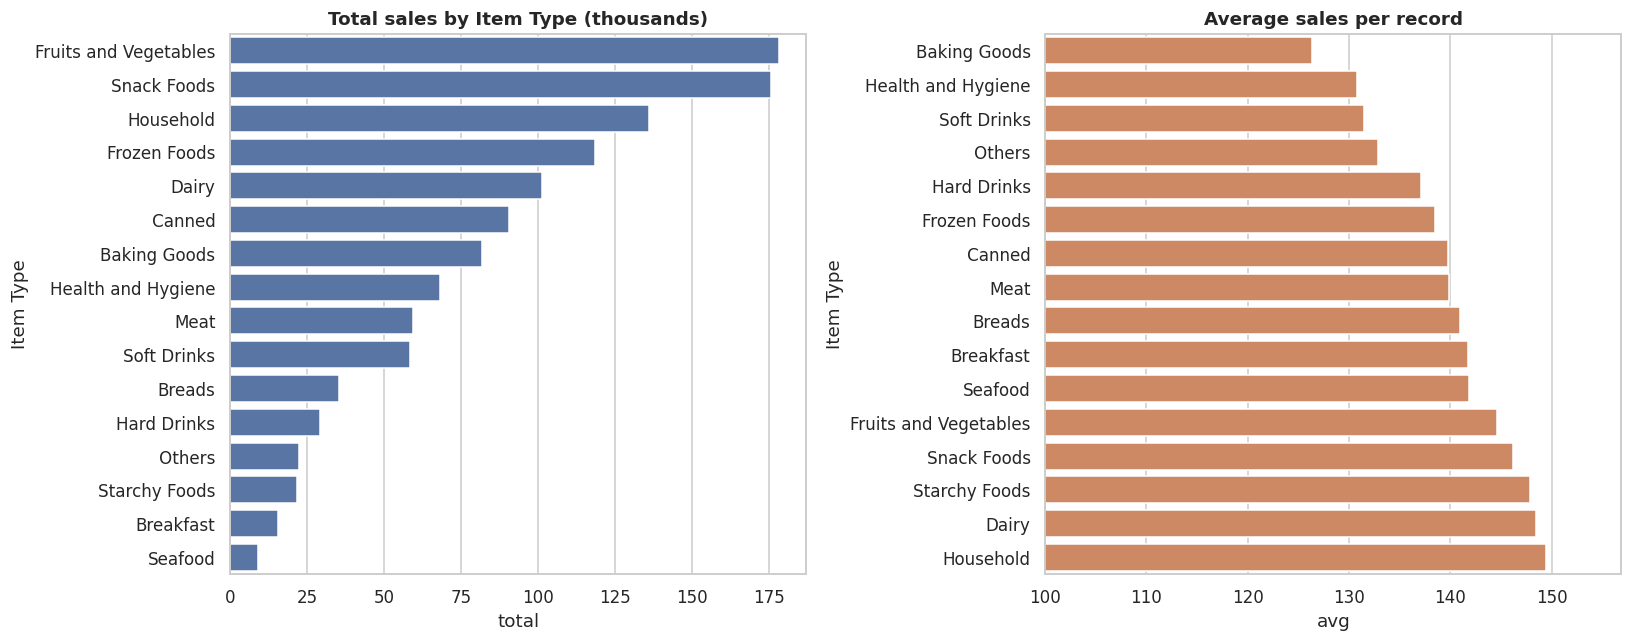

In [10]:
#Objective 3: Find what is driving sales
# Task 3.1 product types: total vs average per record
it = df.groupby("Item Type")["Sales"].agg(total="sum", avg="mean", records="size").sort_values("total", ascending=False)
it["share_%"] = (it["total"] / it["total"].sum() * 100).round(1)
display(it.round(1))

fig, ax = plt.subplots(1, 2, figsize=(15, 6))
sns.barplot(y=it.index, x=it["total"] / 1e3, ax=ax[0], color="#4c72b0"); ax[0].set_title("Total sales by Item Type (thousands)")
s = it.sort_values("avg")
sns.barplot(y=s.index, x=s["avg"], ax=ax[1], color="#dd8452"); ax[1].set_title("Average sales per record"); ax[1].set_xlim(100, None)
plt.tight_layout(); plt.show()

,total,avg,records,outlets,sales_per_outlet
Outlet Type,,,,,
Grocery Store,151939.1,140.3,1083,2,75969.6
Supermarket Type1,787549.9,141.2,5577,6,131258.3
Supermarket Type2,131477.8,141.7,928,1,131477.8
Supermarket Type3,130714.7,139.8,935,1,130714.7


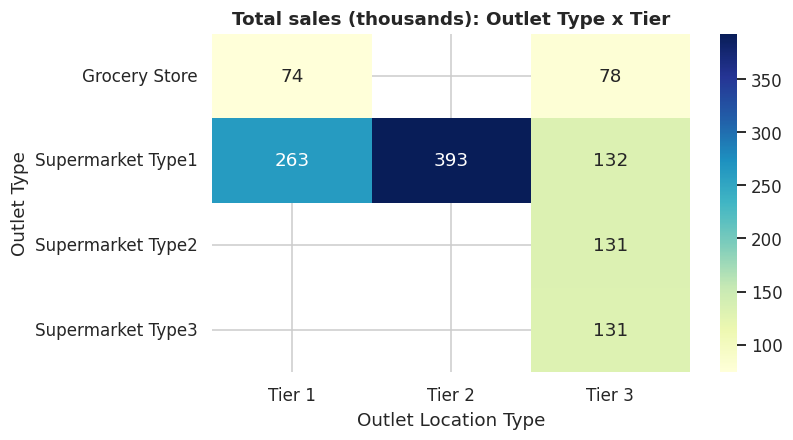

In [11]:
# Task 3.2 outlet performance: total vs per-record
o = df.groupby("Outlet Type")["Sales"].agg(total="sum", avg="mean", records="size")
o["outlets"] = df.groupby("Outlet Type")["Outlet Identifier"].nunique()
o["sales_per_outlet"] = o["total"] / o["outlets"]
display(o.round(1))

pt = df.pivot_table(index="Outlet Type", columns="Outlet Location Type", values="Sales", aggfunc="sum") / 1e3
plt.figure(figsize=(7, 4)); sns.heatmap(pt, annot=True, fmt=".0f", cmap="YlGnBu")
plt.title("Total sales (thousands): Outlet Type x Tier"); plt.show()

                 Item Visibility  Item Weight  Rating  Sales
Item Visibility            1.000       -0.021  -0.004 -0.006
Item Weight               -0.021        1.000   0.004  0.026
Rating                    -0.004        0.004   1.000  0.011
Sales                     -0.006        0.026   0.011  1.000


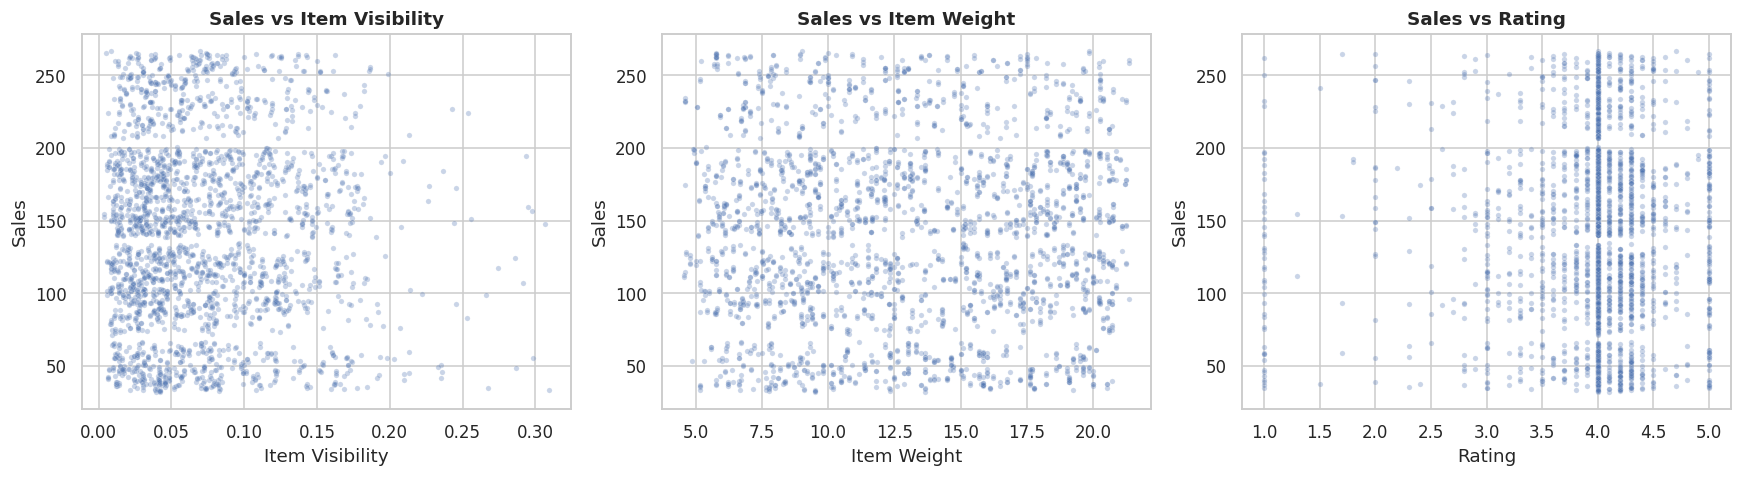

Item Type              p = 0.000 -> significant
Item Fat Content       p = 0.550 -> no real difference
Outlet Type            p = 0.947 -> no real difference
Outlet Location Type   p = 0.981 -> no real difference
Outlet Size            p = 0.401 -> no real difference
Outlet Identifier      p = 0.976 -> no real difference


In [12]:
# Task 3.3 visibility, weight, rating vs sales
num = ["Item Visibility", "Item Weight", "Rating", "Sales"]
print(df[num].corr().round(3))

fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
for a, c in zip(ax, num[:3]):
    sns.scatterplot(data=df.sample(2500, random_state=1), x=c, y="Sales", alpha=.3, s=12, ax=a)
    a.set_title(f"Sales vs {c}")
plt.tight_layout(); plt.show()

# Do average sales per record really differ across groups?
for c in ["Item Type", "Item Fat Content", "Outlet Type", "Outlet Location Type", "Outlet Size", "Outlet Identifier"]:
    h, p = stats.kruskal(*[g["Sales"].values for _, g in df.groupby(c)])
    print(f"{c:22s} p = {p:.3f} -> {'significant' if p < .05 else 'no real difference'}")

In [13]:
# Task 3.4 high vs low performers (top vs bottom quartile of Sales)
df["perf"] = pd.qcut(df["Sales"], 4, labels=["Low", "Mid-Low", "Mid-High", "High"])
print(df[df["perf"].isin(["Low", "High"])].groupby("perf")[["Item Visibility", "Item Weight", "Rating"]].mean().round(3))
print(pd.crosstab(df["Outlet Type"], df["perf"], normalize="index").round(3))

          Item Visibility  Item Weight  Rating
perf                                          
Low                 0.071       12.805   3.965
Mid-Low               NaN          NaN     NaN
Mid-High              NaN          NaN     NaN
High                0.071       13.067   3.965
perf                 Low  Mid-Low  Mid-High   High
Outlet Type                                       
Grocery Store      0.254    0.240     0.263  0.243
Supermarket Type1  0.249    0.251     0.249  0.251
Supermarket Type2  0.247    0.267     0.224  0.262
Supermarket Type3  0.258    0.237     0.264  0.241


In [14]:
#Objective 4: Business decisions (features, models, recommendations)
# Feature engineering
CURRENT_YEAR = 2026
fe = df.copy()
fe["Outlet Age"] = CURRENT_YEAR - fe["Outlet Establishment Year"]
fe["Log Visibility"] = np.log1p(fe["Item Visibility"])
fe["Rel Visibility"] = fe["Item Visibility"] / fe.groupby("Outlet Identifier")["Item Visibility"].transform("mean")

num_f = ["Item Weight", "Log Visibility", "Rel Visibility", "Rating", "Outlet Age"]
cat_f = ["Item Fat Content", "Item Type", "Item Category", "Outlet Size", "Outlet Location Type", "Outlet Type"]
X, y = fe[num_f + cat_f], fe["Sales"]

In [15]:
# Train/test split, preprocessing and model comparison
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from xgboost import XGBRegressor          # already installed in Colab

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=.2, random_state=42)
pre = ColumnTransformer([("num", StandardScaler(), num_f),
                         ("cat", OneHotEncoder(handle_unknown="ignore"), cat_f)])

models = {
    "Baseline (mean)": DummyRegressor(),
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(alpha=10),
    "Random Forest": RandomForestRegressor(n_estimators=100, min_samples_leaf=20, max_features=0.5, n_jobs=-1, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
    "XGBoost": XGBRegressor(n_estimators=300, learning_rate=.05, max_depth=3, subsample=.8, random_state=42),
}
rows = []
for name, m in models.items():
    p = Pipeline([("pre", pre), ("m", m)]).fit(X_tr, y_tr).predict(X_te)
    rows.append(dict(Model=name, RMSE=np.sqrt(mean_squared_error(y_te, p)), MAE=mean_absolute_error(y_te, p), R2=r2_score(y_te, p)))
res = pd.DataFrame(rows).set_index("Model").round(3); res

,RMSE,MAE,R2
Model,,,
Baseline (mean),62.956,52.878,-0.001
Linear Regression,62.307,52.317,0.020
Ridge,62.309,52.328,0.020
Random Forest,54.813,45.255,0.242
Gradient Boosting,58.429,48.568,0.138
XGBoost,57.037,47.526,0.179


In [ ]:
# Hyperparameter tuning
from sklearn.model_selection import RandomizedSearchCV

search = {}
for name, est, grid in [
    ("Random Forest", RandomForestRegressor(n_jobs=-1, random_state=42),
     {"m__n_estimators": [100, 200], "m__max_depth": [4, 6, 8], "m__min_samples_leaf": [20, 40], "m__max_features": ["sqrt", 0.5]}),
    ("Gradient Boosting", GradientBoostingRegressor(random_state=42),
     {"m__n_estimators": [50, 100, 200], "m__learning_rate": [.03, .1], "m__max_depth": [2, 3, 4]})]:
    rs = RandomizedSearchCV(Pipeline([("pre", pre), ("m", est)]), grid, n_iter=8, cv=5,
                            scoring="r2", random_state=42, n_jobs=-1).fit(X_tr, y_tr)
    p = rs.predict(X_te); search[name] = rs
    print(f"{name}: CV R2={rs.best_score_:.3f} | test R2={r2_score(y_te, p):.3f} | "
          f"RMSE={np.sqrt(mean_squared_error(y_te, p)):.2f} | MAE={mean_absolute_error(y_te, p):.2f}")
    print("  best params:", rs.best_params_)

In [ ]:
# Feature importance (permutation, on held-out data)
from sklearn.inspection import permutation_importance
best = search["Random Forest"].best_estimator_
pi = permutation_importance(best, X_te, y_te, n_repeats=10, random_state=42, scoring="r2")
imp = pd.Series(pi.importances_mean, index=X_te.columns).sort_values()
imp.plot.barh(figsize=(7, 4.5), color="#4c72b0"); plt.title("Permutation importance (drop in test R²)"); plt.show()

In [ ]:
# Reality check: is a good R² real, or is the model just recognising products?
from sklearn.model_selection import GroupShuffleSplit

within = df.groupby("Item Identifier")["Sales"].transform("mean")
print(f"Sales variance explained by item identity alone: {1 - ((df['Sales']-within)**2).sum() / ((df['Sales']-df['Sales'].mean())**2).sum():.1%}")

tr_i, te_i = next(GroupShuffleSplit(1, test_size=.2, random_state=42).split(X, y, fe["Item Identifier"]))
rf = Pipeline([("pre", pre), ("m", models["Random Forest"])]).fit(X.iloc[tr_i], y.iloc[tr_i])
print(f"Random Forest R²: random split = {res.loc['Random Forest','R2']:.3f} | unseen-product split = {r2_score(y.iloc[te_i], rf.predict(X.iloc[te_i])):.3f}")

In [ ]:
# Tasks 4.1 to 4.3: contributors and improvement areas
top_items = df.groupby("Item Identifier")["Sales"].sum().sort_values(ascending=False)
print("Top 10 items:\n", top_items.head(10).round(0))
print(f"\nTop 20% of items = {top_items.head(int(len(top_items)*.2)).sum()/top_items.sum():.1%} of sales")

per_outlet = df.groupby(["Outlet Identifier", "Outlet Type", "Outlet Location Type", "Outlet Size"])["Sales"].agg(["sum", "size"]).round(0)
per_outlet["sales_per_record"] = (per_outlet["sum"] / per_outlet["size"]).round(1)
display(per_outlet.sort_values("sum", ascending=False))

# Lowest average-sales categories = candidates for pricing/assortment review
display(it.sort_values("avg").head(3).round(1))